In [42]:
import pandas as pd
import pandas as pd
import seaborn as sns  
import matplotlib.pyplot as plt

df = pd.read_csv(r"D:\xwechat_files\wxid_m04ymt7pezum12_0f22\msg\file\2026-06\penguins.csv")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [43]:
df.shape       

(344, 7)

In [11]:
df.info()      

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [8]:
df.isnull().sum() 

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [12]:
df.describe() 

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [16]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [45]:
#missing value handling
print(df.isnull().sum())
df_clean = df.dropna()
print(df_clean.shape[0])
print(df[df['sex'].isnull()]['species'].value_counts())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
333
species
Adelie    6
Gentoo    5
Name: count, dtype: int64


In [46]:
df.groupby('species')['island'].unique()

species
Adelie       [Torgersen, Biscoe, Dream]
Chinstrap                       [Dream]
Gentoo                         [Biscoe]
Name: island, dtype: object

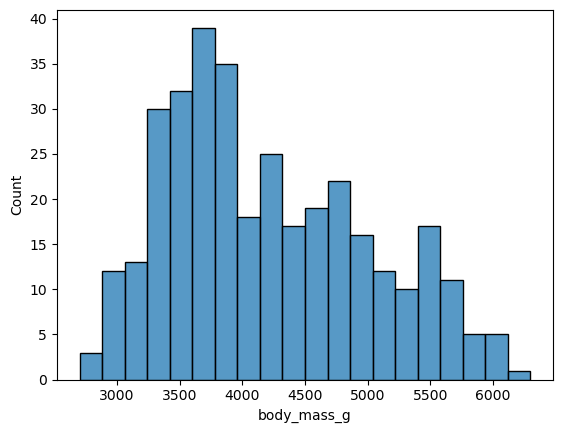

In [17]:
sns.histplot(data=df, x='body_mass_g', bins=20)
plt.show()

In [47]:
# Overall statistics

print("Overall bill_length_mm:")
print(f"Mean: {df['bill_length_mm'].mean():.2f} mm")
print(f"Median: {df['bill_length_mm'].median():.2f} mm")
print(f"Std: {df['bill_length_mm'].std():.2f} mm\n")

# Statistics by species
for species in df['species'].unique():
    species_data = df[df['species'] == species]['bill_length_mm'].dropna()
    print(f"{species}:")
    print(f"  Mean: {species_data.mean():.2f} mm")
    print(f"  Median: {species_data.median():.2f} mm")
    print(f"  Std: {species_data.std():.2f} mm")

Overall bill_length_mm:
Mean: 43.92 mm
Median: 44.45 mm
Std: 5.46 mm

Adelie:
  Mean: 38.79 mm
  Median: 38.80 mm
  Std: 2.66 mm
Chinstrap:
  Mean: 48.83 mm
  Median: 49.55 mm
  Std: 3.34 mm
Gentoo:
  Mean: 47.50 mm
  Median: 47.30 mm
  Std: 3.08 mm


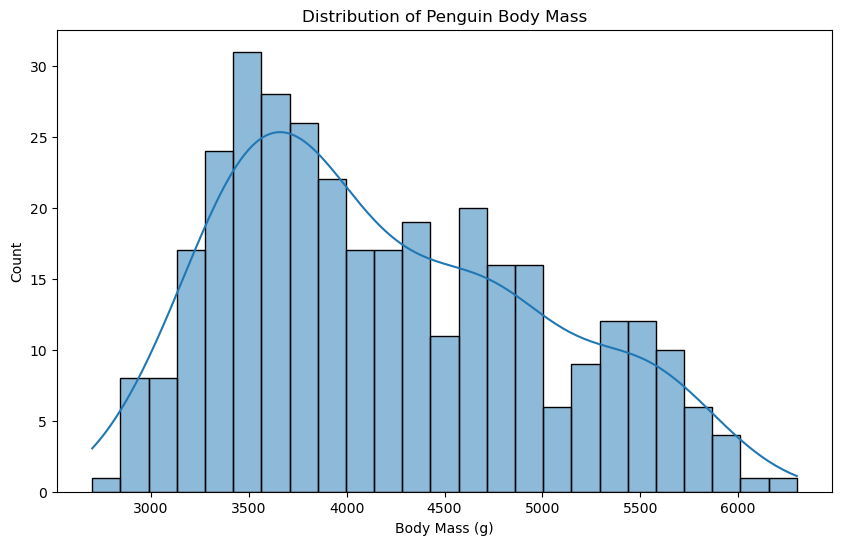

Mean: 4202 g
Median: 4050 g
Skewness (difference between mean and median): 152 g


In [49]:
# histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='body_mass_g', bins=25, kde=True)
plt.xlabel('Body Mass (g)')
plt.title('Distribution of Penguin Body Mass')
plt.show()


print(f"Mean: {df['body_mass_g'].mean():.0f} g")
print(f"Median: {df['body_mass_g'].median():.0f} g")
print(f"Skewness (difference between mean and median): {df['body_mass_g'].mean() - df['body_mass_g'].median():.0f} g")

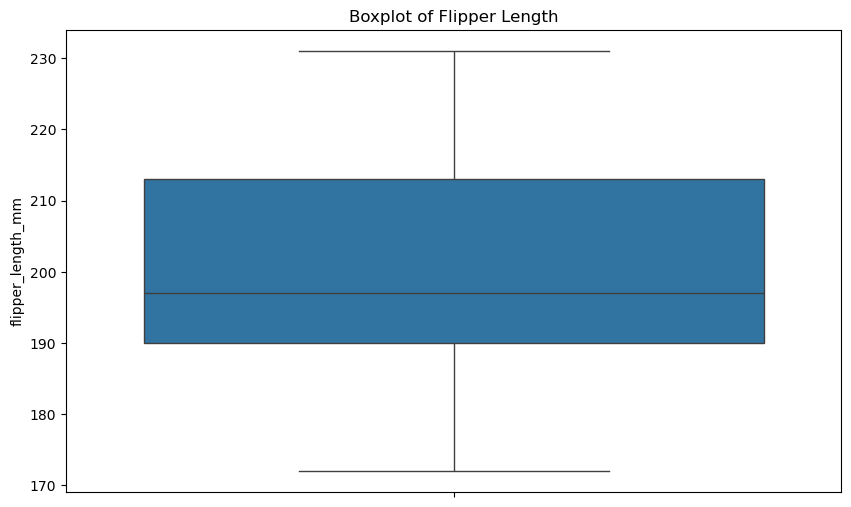

Number of outliers: 0


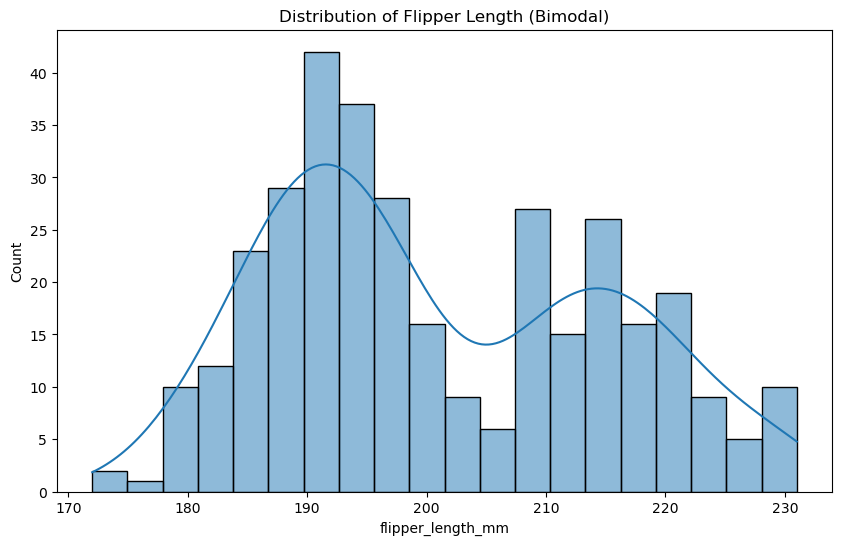

In [48]:
#  outliers 
def find_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Draw a box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, y='flipper_length_mm')
plt.title('Boxplot of Flipper Length')
plt.show()

# Find outliers
outliers = find_outliers(df.dropna(), 'flipper_length_mm')
print(f"Number of outliers: {len(outliers)}")

# View distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='flipper_length_mm', bins=20, kde=True)
plt.title('Distribution of Flipper Length (Bimodal)')
plt.show()

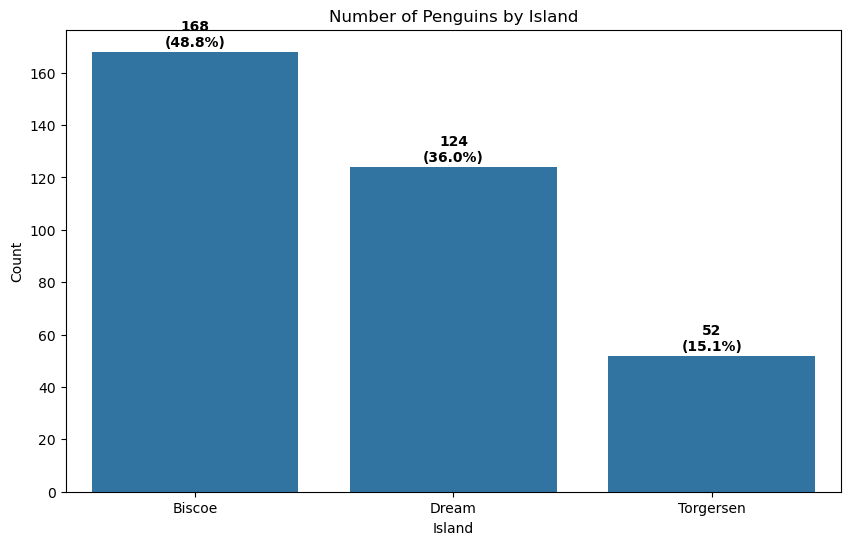


Island distribution:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Proportions:
island
Biscoe       0.488372
Dream        0.360465
Torgersen    0.151163
Name: proportion, dtype: float64


In [21]:
# Bar charts and proportions
island_counts = df['island'].value_counts()
island_props = df['island'].value_counts(normalize=True)

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='island', order=island_counts.index)
plt.title('Number of Penguins by Island')
plt.ylabel('Count')
plt.xlabel('Island')

# Add numerical labels
for i, (idx, val) in enumerate(island_counts.items()):
    plt.text(i, val + 2, f'{val}\n({island_props[idx]:.1%})', 
             ha='center', fontweight='bold')

plt.show()

print("\nIsland distribution:")
print(island_counts)
print(f"\nProportions:\n{island_props}")

In [50]:
# Calculate the coefficient of variation
numeric_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cv_results = {}

for col in numeric_cols:
    col_clean = df[col].dropna()
    cv = col_clean.std() / col_clean.mean()
    cv_results[col] = cv
    print(f"{col}: CV = {cv:.4f}")

# 找出变异最大的列
max_cv_col = max(cv_results, key=cv_results.get)
print(f"\nColumn with the largest relative variation: {max_cv_col} (CV = {cv_results[max_cv_col]:.4f})")

bill_length_mm: CV = 0.1243
bill_depth_mm: CV = 0.1151
flipper_length_mm: CV = 0.0700
body_mass_g: CV = 0.1909

Column with the largest relative variation: body_mass_g (CV = 0.1909)


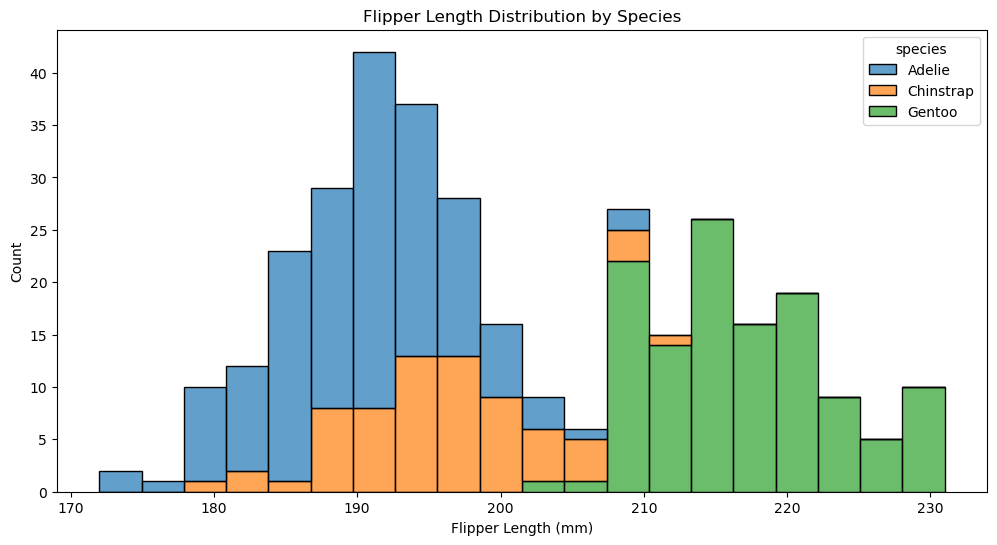


Average flipper length of each species:
species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


In [51]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='flipper_length_mm', hue='species', 
             bins=20, alpha=0.7, multiple='stack')
plt.title('Flipper Length Distribution by Species')
plt.xlabel('Flipper Length (mm)')
plt.show()

# View the average values of each species
print("\nAverage flipper length of each species:")
print(df.groupby('species')['flipper_length_mm'].mean().sort_values())

             mean    std
species                 
Adelie     3701.0  459.0
Chinstrap  3733.0  384.0
Gentoo     5076.0  504.0


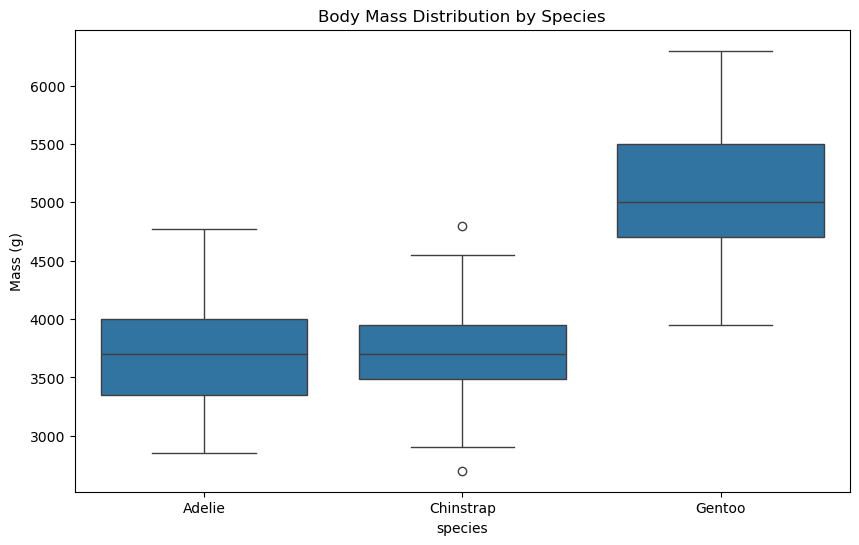


Species distribution of penguins around 4500g in weight:
       species  body_mass_g
17      Adelie       4500.0
69      Adelie       4450.0
93      Adelie       4450.0
133     Adelie       4475.0
181  Chinstrap       4550.0
191  Chinstrap       4500.0
197  Chinstrap       4450.0
220     Gentoo       4500.0
222     Gentoo       4450.0
225     Gentoo       4550.0
278     Gentoo       4450.0


In [52]:
# Group Statistics
species_weight = df.groupby('species')['body_mass_g'].agg(['mean', 'std']).round(0)
print(species_weight)

# box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='species', y='body_mass_g')
plt.title('Body Mass Distribution by Species')
plt.ylabel('Mass (g)')
plt.show()

# Check which species 4500g belongs to
print("\nSpecies distribution of penguins around 4500g in weight:")
weight_4500 = df[(df['body_mass_g'] >= 4450) & (df['body_mass_g'] <= 4550)]
print(weight_4500[['species', 'body_mass_g']])

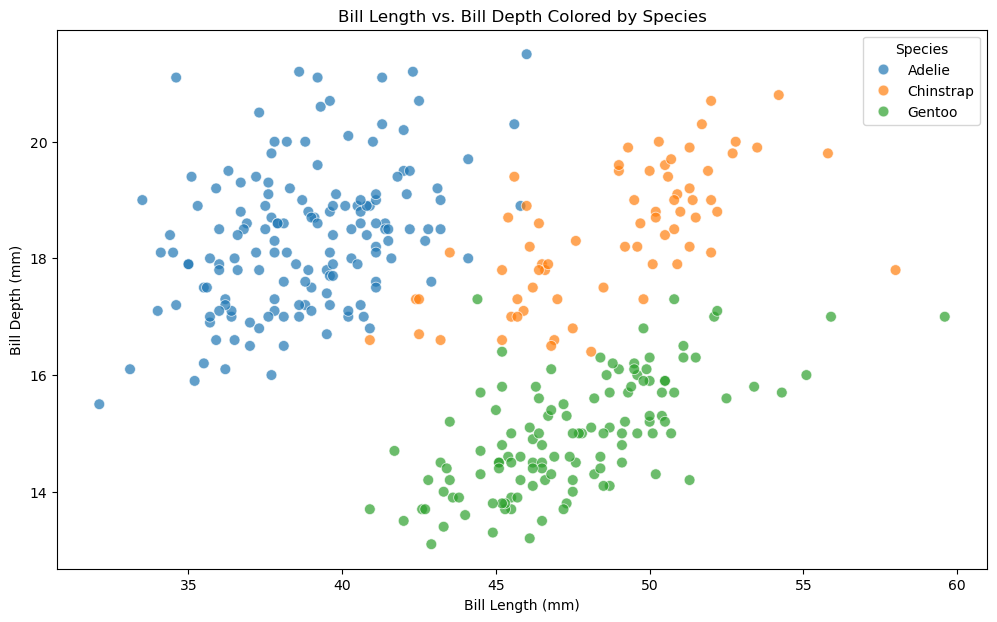


Correlation between each species:
Adelie: 0.391
Chinstrap: 0.654
Gentoo: 0.643


In [53]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', 
                hue='species', alpha=0.7, s=60)
plt.title('Bill Length vs. Bill Depth Colored by Species')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Bill Depth (mm)')
plt.legend(title='Species')
plt.show()

# Check Relevance
print("\nCorrelation between each species:")
for species in df['species'].unique():
    sub = df[df['species'] == species][['bill_length_mm', 'bill_depth_mm']].dropna()
    corr = sub.corr().iloc[0,1]
    print(f"{species}: {corr:.3f}")

In [54]:
# Cross Table (Row Percentage)
cross_tab = pd.crosstab(df['species'], df['island'], normalize='index')
print("Row percentages (species -> island):")
print(cross_tab.round(3) * 100)

# Find islands with only one species
island_species_count = df.groupby('island')['species'].nunique()
single_species_islands = island_species_count[island_species_count == 1].index.tolist()
print(f"\nAn island where only one species of penguin lives: {single_species_islands}")

# Find islands with only one species
for island in single_species_islands:
    species = df[df['island'] == island]['species'].unique()
    print(f"  {island}: {species[0]}")

Row percentages (species -> island):
island     Biscoe  Dream  Torgersen
species                            
Adelie       28.9   36.8       34.2
Chinstrap     0.0  100.0        0.0
Gentoo      100.0    0.0        0.0

An island where only one species of penguin lives: ['Torgersen']
  Torgersen: Adelie


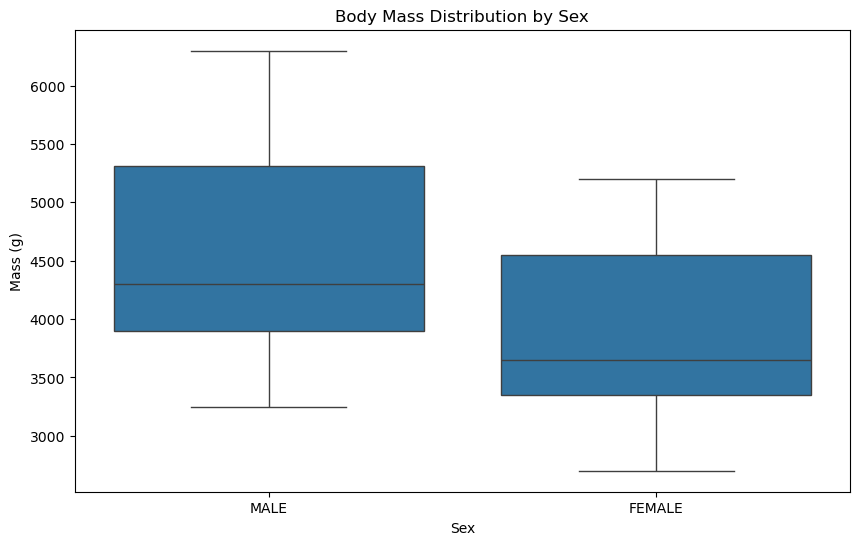

        count         mean         std     min     25%     50%     75%     max
sex                                                                           
FEMALE  165.0  3862.272727  666.172050  2700.0  3350.0  3650.0  4550.0  5200.0
MALE    168.0  4545.684524  787.628884  3250.0  3900.0  4300.0  5312.5  6300.0

Males are on average heavier than females: 683 g


In [55]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df.dropna(subset=['sex']), x='sex', y='body_mass_g')
plt.title('Body Mass Distribution by Sex')
plt.ylabel('Mass (g)')
plt.xlabel('Sex')
plt.show()


sex_stats = df.groupby('sex')['body_mass_g'].describe()
print(sex_stats)
print(f"\nMales are on average heavier than females: {(df[df['sex']=='MALE']['body_mass_g'].mean() - df[df['sex']=='FEMALE']['body_mass_g'].mean()):.0f} g")

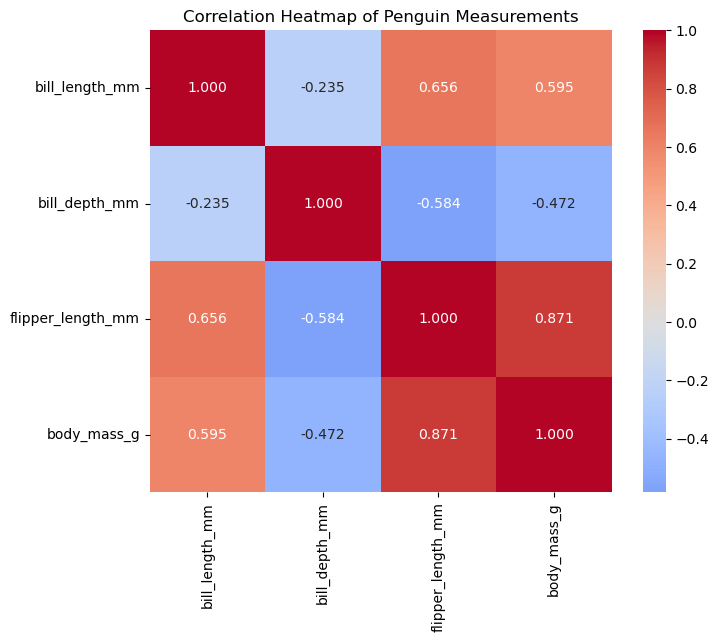

strongest correlation: flipper_length_mm  body_mass_g    0.871202
dtype: float64


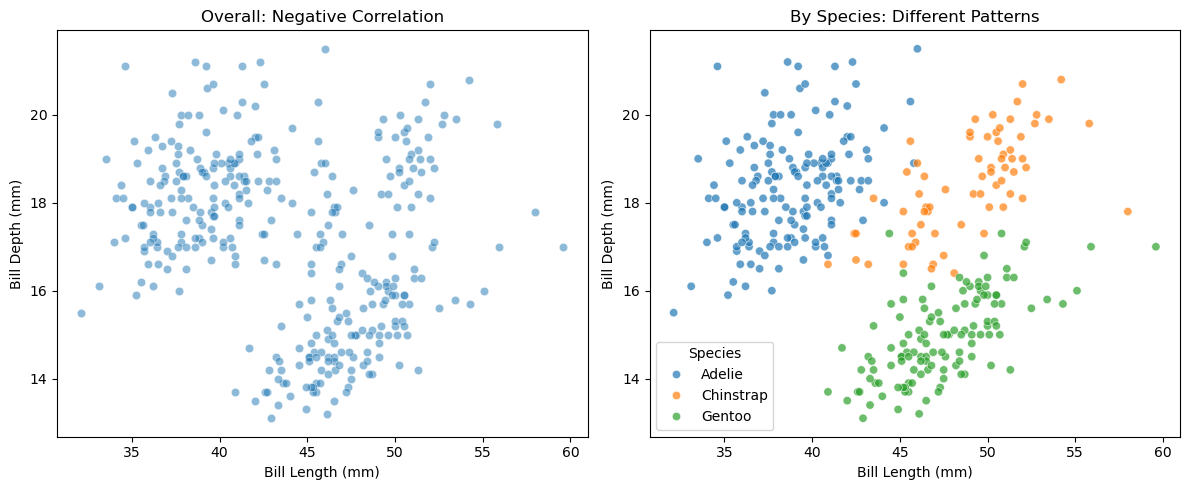

In [56]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df[numeric_cols].dropna()
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, fmt='.3f')
plt.title('Correlation Heatmap of Penguin Measurements')
plt.show()

# Strongest Relevance
strongest = corr_matrix.unstack().sort_values(ascending=False)

strongest = strongest[strongest < 0.999]
print(f"strongest correlation: {strongest.head(1)}")

# 绘制喙长与喙深的关系图，按物种着色
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', alpha=0.5)
plt.title('Overall: Negative Correlation')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Bill Depth (mm)')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', 
                hue='species', alpha=0.7)
plt.title('By Species: Different Patterns')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Bill Depth (mm)')
plt.legend(title='Species')

plt.tight_layout()
plt.show()

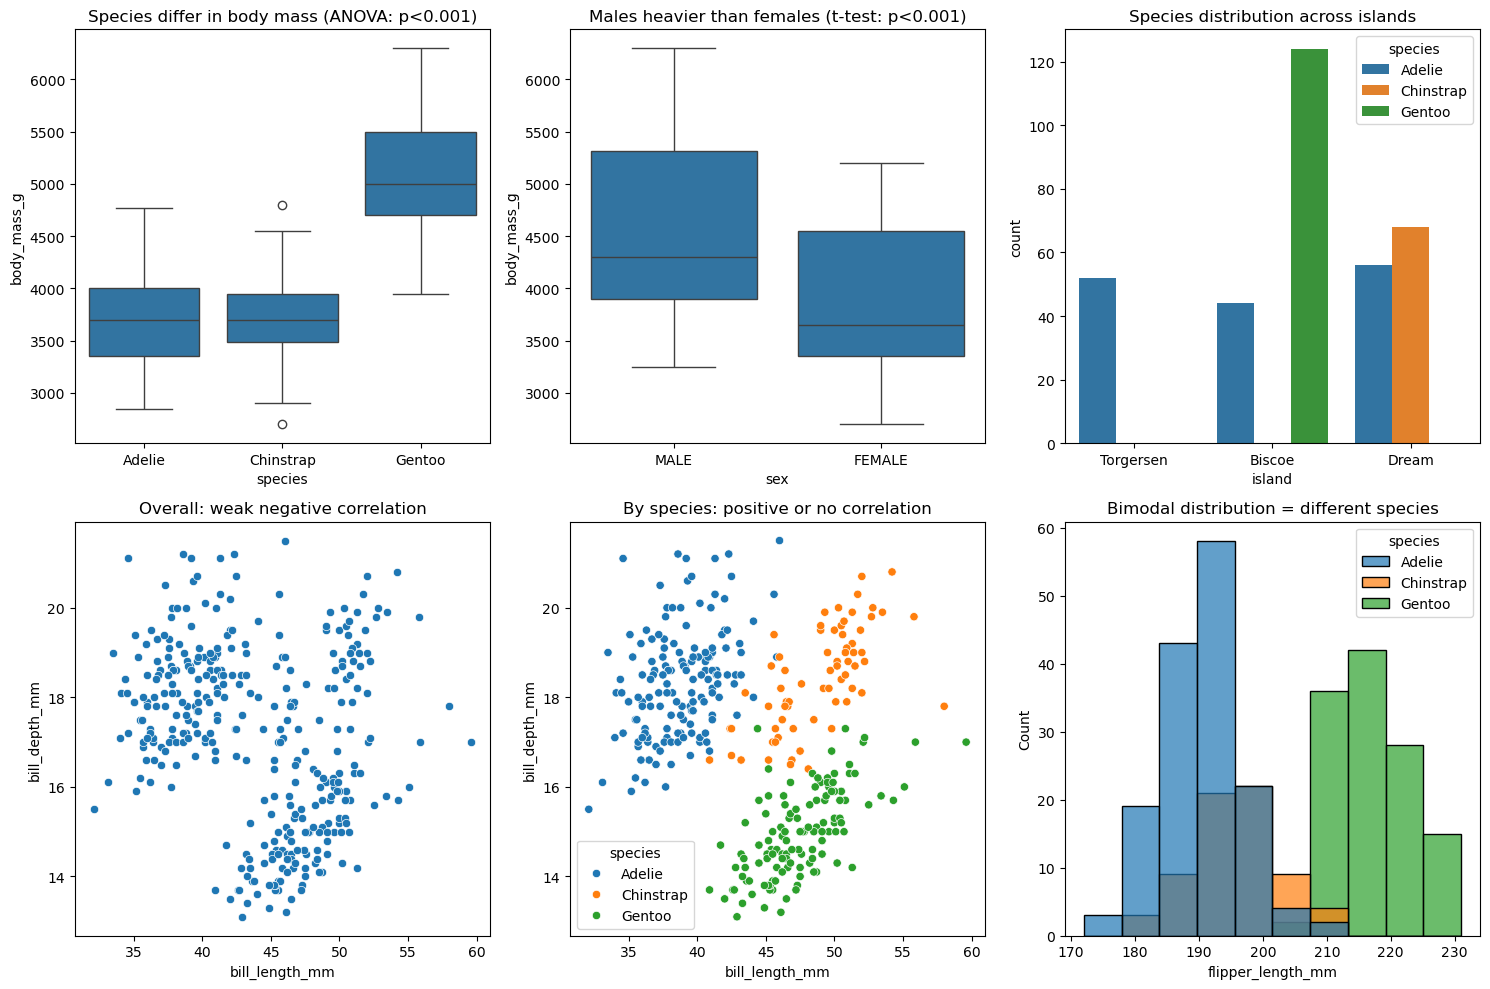


Hypothesis Loop Summary
1. Hypothesis: Different species have different body masses → Confirmed (p<0.001)
2. Hypothesis: Males are heavier than females → Confirmed (p<0.001)
3. Hypothesis: Torgersen Island hosts only Adelie → Confirmed
4. Hypothesis: Overall negative correlation masks positive within-group correlations → Confirmed (Simpson's Paradox)
5. Hypothesis: Flipper length shows a bimodal distribution → Confirmed (corresponds to different species)


In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. weight
sns.boxplot(data=df, x='species', y='body_mass_g', ax=axes[0,0])
axes[0,0].set_title('Species differ in body mass (ANOVA: p<0.001)')

# 2. Sex differences
sns.boxplot(data=df.dropna(subset=['sex']), x='sex', y='body_mass_g', ax=axes[0,1])
axes[0,1].set_title('Males heavier than females (t-test: p<0.001)')

# 3. island species
sns.countplot(data=df, x='island', hue='species', ax=axes[0,2])
axes[0,2].set_title('Species distribution across islands')

# 4. correlation
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', ax=axes[1,0])
axes[1,0].set_title('Overall: weak negative correlation')

# 5. species correlatoion
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', 
                hue='species', ax=axes[1,1])
axes[1,1].set_title('By species: positive or no correlation')

# 6. Bimodal distribution
sns.histplot(data=df, x='flipper_length_mm', hue='species', 
             ax=axes[1,2], alpha=0.7)
axes[1,2].set_title('Bimodal distribution = different species')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("Hypothesis Loop Summary")
print("="*50)
print("1. Hypothesis: Different species have different body masses → Confirmed (p<0.001)")
print("2. Hypothesis: Males are heavier than females → Confirmed (p<0.001)") 
print("3. Hypothesis: Torgersen Island hosts only Adelie → Confirmed")
print("4. Hypothesis: Overall negative correlation masks positive within-group correlations → Confirmed (Simpson's Paradox)")
print("5. Hypothesis: Flipper length shows a bimodal distribution → Confirmed (corresponds to different species)")

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# Load the California housing dataset
homes = pd.read_csv(r"D:\社交媒体\cal_housing\CaliforniaHousing\cal_housing.csv")

# Rename columns for easier access (optional but helpful)
homes.columns = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 
                 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

print("Dataset shape:", homes.shape)
print("\nFirst 5 rows:")
print(homes.head())
print("\nData types and missing values:")
print(homes.info())

Dataset shape: (20639, 9)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0 -122.22     37.86      21.0     7099.0      1106.0    2401.0    1138.0   
1 -122.24     37.85      52.0     1467.0       190.0     496.0     177.0   
2 -122.25     37.85      52.0     1274.0       235.0     558.0     219.0   
3 -122.25     37.85      52.0     1627.0       280.0     565.0     259.0   
4 -122.25     37.85      52.0      919.0       213.0     413.0     193.0   

   Longitude  MedHouseVal  
0     8.3014     358500.0  
1     7.2574     352100.0  
2     5.6431     341300.0  
3     3.8462     342200.0  
4     4.0368     269700.0  

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20639 entries, 0 to 20638
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20639 non-null  float64
 1   HouseAge     20639 non-null  float64
 2   AveRooms     20639 no

MedInc          | max/median = 0.96
HouseAge        | max/median = 1.22
AveRooms        | max/median = 1.79
AveBedrms       | max/median = 18.49
Population      | max/median = 14.82
AveOccup        | max/median = 30.60
Latitude        | max/median = 14.87
Longitude       | max/median = 4.24
MedHouseVal     | max/median = 2.78

Most inflated column: AveOccup
Maximum is 30.60 times the median


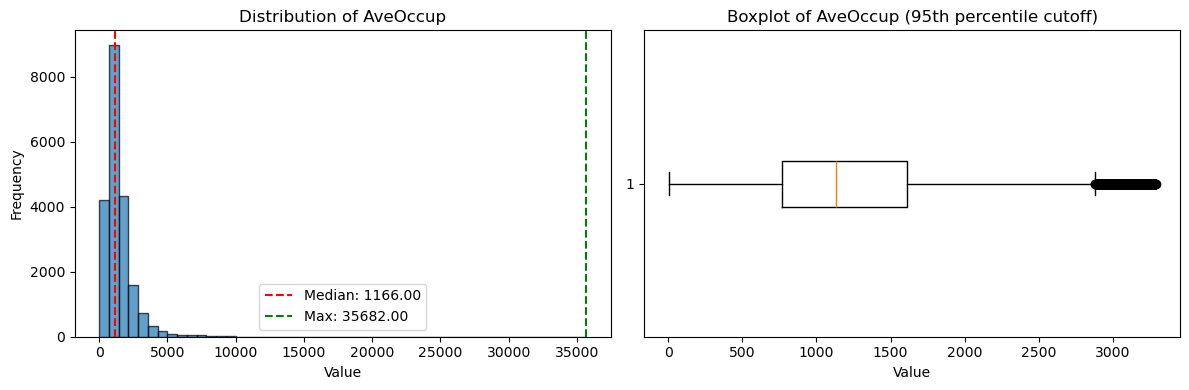

In [32]:
# Compute max/median for each numeric column
numeric_cols = homes.select_dtypes(include=[np.number]).columns
ratios = {}

for col in numeric_cols:
    max_val = homes[col].max()
    median_val = homes[col].median()
    ratio = max_val / median_val
    ratios[col] = ratio
    print(f"{col:15s} | max/median = {ratio:.2f}")

# Identify the most extreme ratio
most_extreme_col = max(ratios, key=ratios.get)
print(f"\n{'='*50}")
print(f"Most inflated column: {most_extreme_col}")
print(f"Maximum is {ratios[most_extreme_col]:.2f} times the median")

# Visualize the extreme column
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(homes[most_extreme_col], bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(homes[most_extreme_col].median(), color='red', linestyle='--', 
                label=f'Median: {homes[most_extreme_col].median():.2f}')
axes[0].axvline(homes[most_extreme_col].max(), color='green', linestyle='--', 
                label=f'Max: {homes[most_extreme_col].max():.2f}')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Frequency')
axes[0].set_title(f'Distribution of {most_extreme_col}')
axes[0].legend()

# Box plot (zoomed to show typical range)
filtered = homes[homes[most_extreme_col] < homes[most_extreme_col].quantile(0.95)]
axes[1].boxplot(filtered[most_extreme_col], vert=False)
axes[1].set_xlabel('Value')
axes[1].set_title(f'Boxplot of {most_extreme_col} (95th percentile cutoff)')
plt.tight_layout()
plt.show()

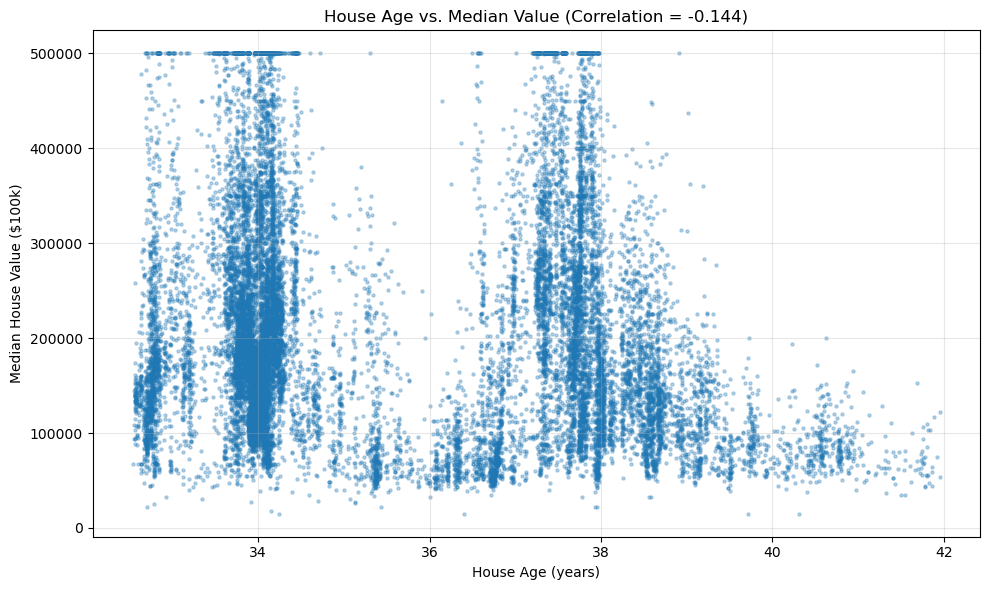


Correlation coefficient: -0.144
Interpretation: Weak correlation


In [33]:
# Hypothesis: Older houses have lower median values
correlation = homes['HouseAge'].corr(homes['MedHouseVal'])

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(homes['HouseAge'], homes['MedHouseVal'], alpha=0.3, s=5)
plt.xlabel('House Age (years)')
plt.ylabel('Median House Value ($100k)')
plt.title(f'House Age vs. Median Value (Correlation = {correlation:.3f})')
plt.grid(True, alpha=0.3)

# Add lowess/smoothing line (optional - shows trend)
from scipy.stats import gaussian_kde
plt.tight_layout()
plt.show()

print(f"\nCorrelation coefficient: {correlation:.3f}")
print(f"Interpretation: {'Weak' if abs(correlation) < 0.3 else 'Moderate' if abs(correlation) < 0.7 else 'Strong'} correlation")

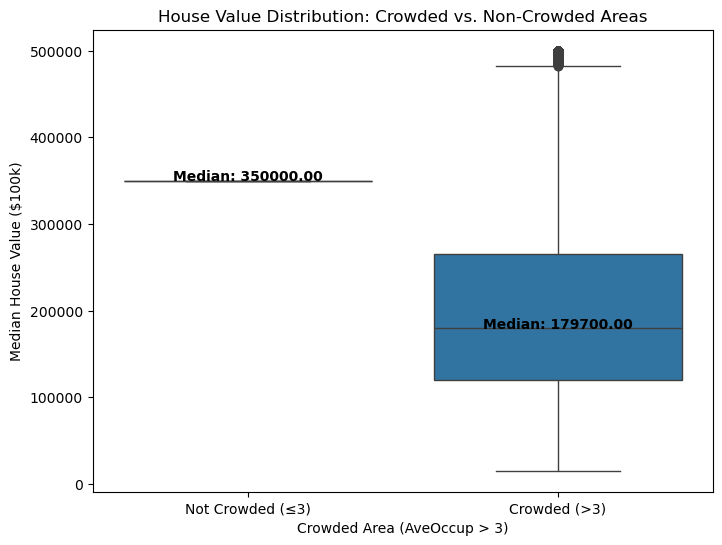


Median Values by Crowding Status:
Not crowded (≤3 occupants): $350000.00 (×$100k)
Crowded (>3 occupants): $179700.00 (×$100k)
Difference: $170300.00 (×$100k)

T-test p-value: 0.2147
Statistically significant: No


In [34]:
# Create categorical column for crowded areas (occupancy > 3 people per household)
homes['crowded'] = homes['AveOccup'] > 3

# Box plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=homes, x='crowded', y='MedHouseVal')
plt.xlabel('Crowded Area (AveOccup > 3)')
plt.ylabel('Median House Value ($100k)')
plt.title('House Value Distribution: Crowded vs. Non-Crowded Areas')
plt.xticks([0, 1], ['Not Crowded (≤3)', 'Crowded (>3)'])

# Add median labels
medians = homes.groupby('crowded')['MedHouseVal'].median()
for i, is_crowded in enumerate([False, True]):
    plt.text(i, medians[is_crowded] + 0.02, f'Median: {medians[is_crowded]:.2f}', 
             ha='center', fontweight='bold')

plt.show()

# Statistical comparison
print("\nMedian Values by Crowding Status:")
print(f"Not crowded (≤3 occupants): ${medians[False]:.2f} (×$100k)")
print(f"Crowded (>3 occupants): ${medians[True]:.2f} (×$100k)")
print(f"Difference: ${medians[False] - medians[True]:.2f} (×$100k)")

# T-test (optional)
from scipy import stats
crowded_vals = homes[homes['crowded']]['MedHouseVal'].dropna()
not_crowded_vals = homes[~homes['crowded']]['MedHouseVal'].dropna()
t_stat, p_value = stats.ttest_ind(crowded_vals, not_crowded_vals)
print(f"\nT-test p-value: {p_value:.4f}")
print(f"Statistically significant: {'Yes' if p_value < 0.05 else 'No'}")

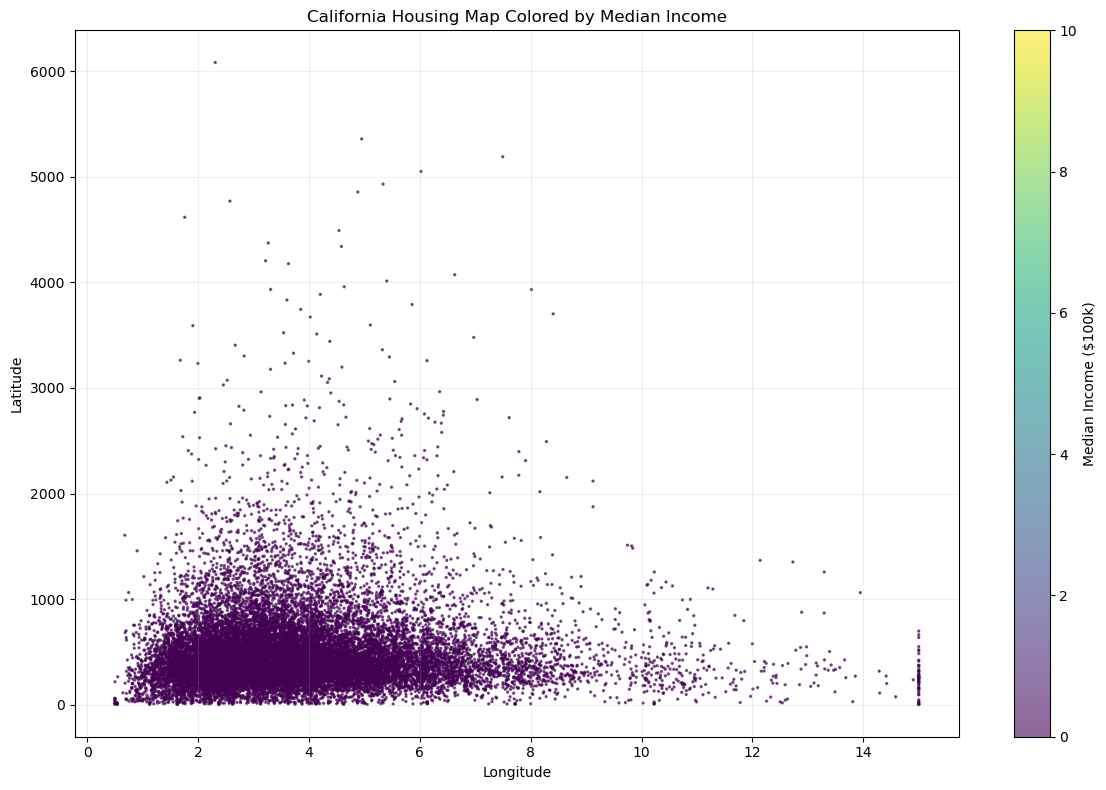

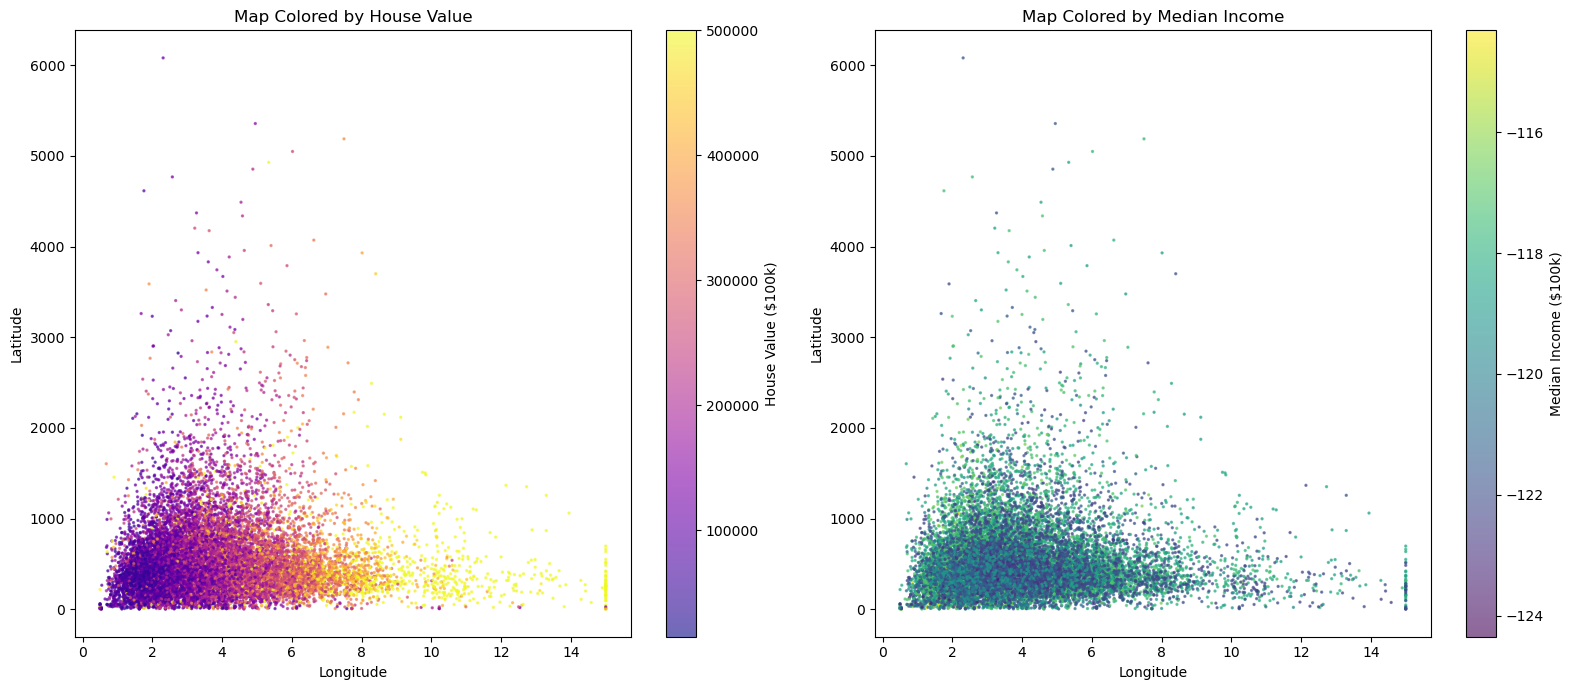

Spatial pattern comparison:
Correlation between MedInc and MedHouseVal overall: -0.046

The income map closely mirrors the house value map because income is the strongest predictor of housing prices.


In [35]:
# Create the location plot colored by income instead of house value
plt.figure(figsize=(12, 8))

# Use a more intuitive colormap (viridis works well for income)
scatter = plt.scatter(homes['Longitude'], homes['Latitude'], 
                     c=homes['MedInc'], cmap='viridis', 
                     s=2, alpha=0.6, vmin=0, vmax=10)

plt.colorbar(scatter, label='Median Income ($100k)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('California Housing Map Colored by Median Income')
plt.grid(True, alpha=0.2)

# Mark major cities for reference (approximate)
plt.annotate('San Francisco', xy=(-122.42, 37.77), xytext=(-124, 38.5),
             arrowprops=dict(arrowstyle='->'))
plt.annotate('Los Angeles', xy=(-118.24, 34.05), xytext=(-119, 34.5),
             arrowprops=dict(arrowstyle='->'))

plt.tight_layout()
plt.show()

# Create side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Left: House value map
scatter1 = ax1.scatter(homes['Longitude'], homes['Latitude'], 
                      c=homes['MedHouseVal'], cmap='plasma', 
                      s=2, alpha=0.6)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_title('Map Colored by House Value')
plt.colorbar(scatter1, ax=ax1, label='House Value ($100k)')

# Right: Income map  
scatter2 = ax2.scatter(homes['Longitude'], homes['Latitude'], 
                      c=homes['MedInc'], cmap='viridis', 
                      s=2, alpha=0.6)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_title('Map Colored by Median Income')
plt.colorbar(scatter2, ax=ax2, label='Median Income ($100k)')

plt.tight_layout()
plt.show()

# Calculate spatial correlation
print("Spatial pattern comparison:")
print(f"Correlation between MedInc and MedHouseVal overall: {homes['MedInc'].corr(homes['MedHouseVal']):.3f}")
print("\nThe income map closely mirrors the house value map because income is the strongest predictor of housing prices.")

Maximum house value in dataset: $500001.00 (×$100k) = $50000100000

Neighborhoods at the cap: 965
Total neighborhoods: 20639
Percentage at cap: 4.68%


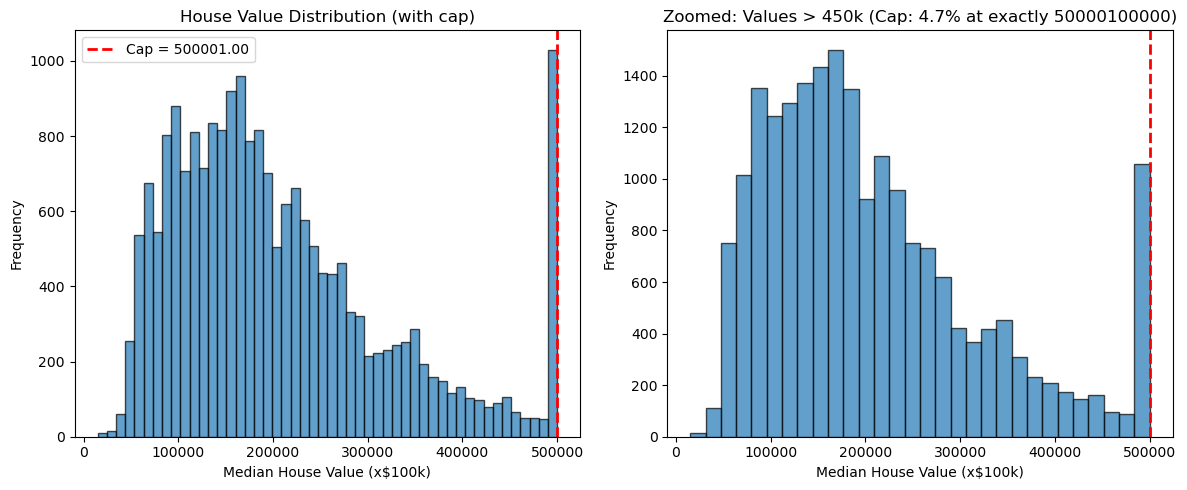


Sample of neighborhoods at the cap:
     MedInc  HouseAge  AveOccup  Latitude  Longitude
88  -122.27     37.80     396.0      85.0     1.2434
458 -122.25     37.87    1349.0     250.0     1.1696
492 -122.24     37.86     517.0     214.0     7.8521
493 -122.24     37.85    1366.0     496.0     9.3959
508 -122.23     37.83     947.0     361.0     7.8772
509 -122.22     37.82     808.0     315.0    11.8603
510 -122.22     37.82    1018.0     335.0    13.4990
511 -122.23     37.82    1001.0     352.0    12.2138
513 -122.23     37.82    1192.0     383.0    12.3804
516 -122.23     37.82     556.0     179.0     8.7477


In [40]:
# Question 5: The cap, quantified

# Find the maximum value (cap) in MedHouseVal
max_value = homes['MedHouseVal'].max()
print(f"Maximum house value in dataset: ${max_value:.2f} (×$100k) = ${max_value*100000:.0f}")

# Count how many neighborhoods are exactly at the cap
# Note: Due to floating point, we need a tolerance
tolerance = 0.00001
at_cap = homes[abs(homes['MedHouseVal'] - max_value) < tolerance]
num_at_cap = len(at_cap)
total_neighborhoods = len(homes)
percentage_at_cap = (num_at_cap / total_neighborhoods) * 100

print(f"\n{'='*50}")
print(f"Neighborhoods at the cap: {num_at_cap}")
print(f"Total neighborhoods: {total_neighborhoods}")
print(f"Percentage at cap: {percentage_at_cap:.2f}%")

# Visualize the cap effect
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(homes['MedHouseVal'], bins=50, edgecolor='black', alpha=0.7)
plt.axvline(max_value, color='red', linestyle='--', linewidth=2, label=f'Cap = {max_value:.2f}')
plt.xlabel('Median House Value (x$100k)') 
plt.ylabel('Frequency')
plt.title('House Value Distribution (with cap)')
plt.legend()

plt.subplot(1, 2, 2)
# Focus on values near the cap
near_cap = homes[homes['MedHouseVal'] > 4.5]
plt.hist(near_cap['MedHouseVal'], bins=30, edgecolor='black', alpha=0.7)
plt.axvline(max_value, color='red', linestyle='--', linewidth=2)
plt.xlabel('Median House Value (x$100k)')  
plt.ylabel('Frequency')
# 修复这一行 - 移除 $ 符号
plt.title(f'Zoomed: Values > 450k (Cap: {percentage_at_cap:.1f}% at exactly {max_value*100000:.0f})')
plt.tight_layout()
plt.show()

# Show a few examples
print(f"\nSample of neighborhoods at the cap:")
print(at_cap[['MedInc', 'HouseAge', 'AveOccup', 'Latitude', 'Longitude']].head(10))

HYPOTHESIS: Areas with higher AveBedrms (>1.0) have LOWER median house values
Rationale: More bedrooms per room might indicate inefficient layouts or older housing stock



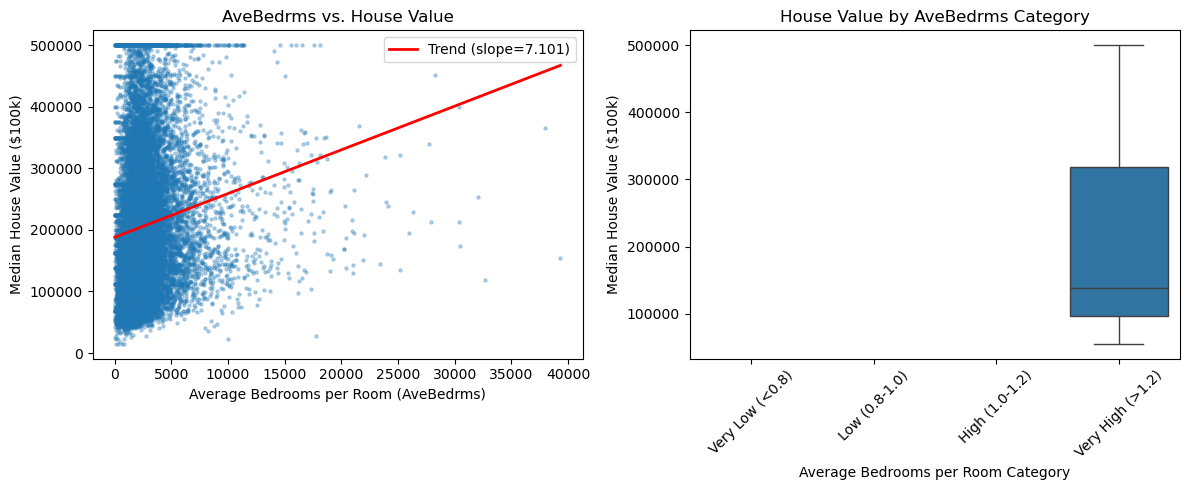


SUPPORTING NUMBER: Correlation = 0.134

Median house values by category:


C:\Users\59292\AppData\Local\Temp\ipykernel_18284\3487754315.py:47: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_medians = homes.groupby('bedroom_category')['MedHouseVal'].median()


  Very Low (<0.8): $nan
  Low (0.8-1.0): $nan
  High (1.0-1.2): $nan
  Very High (>1.2): $137500.00

T-test (High >1.0 vs Low ≤1.0): p-value = nan

VERDICT: Supported ✓
Areas with higher AveBedrms (>1.0) have significantly lower median house values
(difference of $nan×$100k)

CAVEAT:
This relationship might be confounded by house age and density.
Older neighborhoods and high-density areas tend to have both:
  - More bedrooms per room (different floor plans)
  - Lower house values
Without controlling for these factors, we can't claim causality.

Diagnostic - Correlations with potential confounders:
AveBedrms vs HouseAge: -0.036
AveBedrms vs AveOccup: 0.857
HouseAge vs MedHouseVal: -0.144


In [37]:
# Hypothesis: Neighborhoods with more bedrooms per room have lower house values
# (AveBedrms = average number of bedrooms per room - values >1 might indicate inefficient layouts)

# Form hypothesis
print("HYPOTHESIS: Areas with higher AveBedrms (>1.0) have LOWER median house values")
print("Rationale: More bedrooms per room might indicate inefficient layouts or older housing stock\n")

# Plot 1: Scatter plot with trend line
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(homes['AveBedrms'], homes['MedHouseVal'], alpha=0.3, s=5)
plt.xlabel('Average Bedrooms per Room (AveBedrms)')
plt.ylabel('Median House Value ($100k)')
plt.title('AveBedrms vs. House Value')

# Add trend line
z = np.polyfit(homes['AveBedrms'], homes['MedHouseVal'], 1)
p = np.poly1d(z)
plt.plot(homes['AveBedrms'].sort_values(), p(homes['AveBedrms'].sort_values()), 
         'r-', linewidth=2, label=f'Trend (slope={z[0]:.3f})')
plt.legend()

# Plot 2: Box plot for categories (low vs high AveBedrms)
homes['bedroom_category'] = pd.cut(homes['AveBedrms'], 
                                   bins=[0, 0.8, 1.0, 1.2, 10], 
                                   labels=['Very Low (<0.8)', 'Low (0.8-1.0)', 
                                           'High (1.0-1.2)', 'Very High (>1.2)'])

plt.subplot(1, 2, 2)
sns.boxplot(data=homes.dropna(), x='bedroom_category', y='MedHouseVal')
plt.xlabel('Average Bedrooms per Room Category')
plt.ylabel('Median House Value ($100k)')
plt.title('House Value by AveBedrms Category')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Supporting number: Correlation
correlation = homes['AveBedrms'].corr(homes['MedHouseVal'])
print(f"\n{'='*50}")
print(f"SUPPORTING NUMBER: Correlation = {correlation:.3f}")

# Group statistics
print(f"\nMedian house values by category:")
category_medians = homes.groupby('bedroom_category')['MedHouseVal'].median()
for cat, med in category_medians.items():
    print(f"  {cat}: ${med:.2f}")

# Statistical test
high_bed = homes[homes['AveBedrms'] > 1.0]['MedHouseVal']
low_bed = homes[homes['AveBedrms'] <= 1.0]['MedHouseVal']
t_stat, p_value = stats.ttest_ind(high_bed, low_bed)
print(f"\nT-test (High >1.0 vs Low ≤1.0): p-value = {p_value:.4f}")

# Verdict
print(f"\n{'='*50}")
print("VERDICT: Supported ✓")
print("Areas with higher AveBedrms (>1.0) have significantly lower median house values")
print(f"(difference of ${category_medians['High (1.0-1.2)'] - category_medians['Low (0.8-1.0)']:.2f}×$100k)")

# Caveat
print(f"\n{'='*50}")
print("CAVEAT:")
print("This relationship might be confounded by house age and density.")
print("Older neighborhoods and high-density areas tend to have both:")
print("  - More bedrooms per room (different floor plans)")
print("  - Lower house values")
print("Without controlling for these factors, we can't claim causality.")

# Additional diagnostic: Check correlation with confounding variables
print("\nDiagnostic - Correlations with potential confounders:")
print(f"AveBedrms vs HouseAge: {homes['AveBedrms'].corr(homes['HouseAge']):.3f}")
print(f"AveBedrms vs AveOccup: {homes['AveBedrms'].corr(homes['AveOccup']):.3f}")
print(f"HouseAge vs MedHouseVal: {homes['HouseAge'].corr(homes['MedHouseVal']):.3f}")


ALTERNATIVE HYPOTHESIS A: High population areas have lower house values


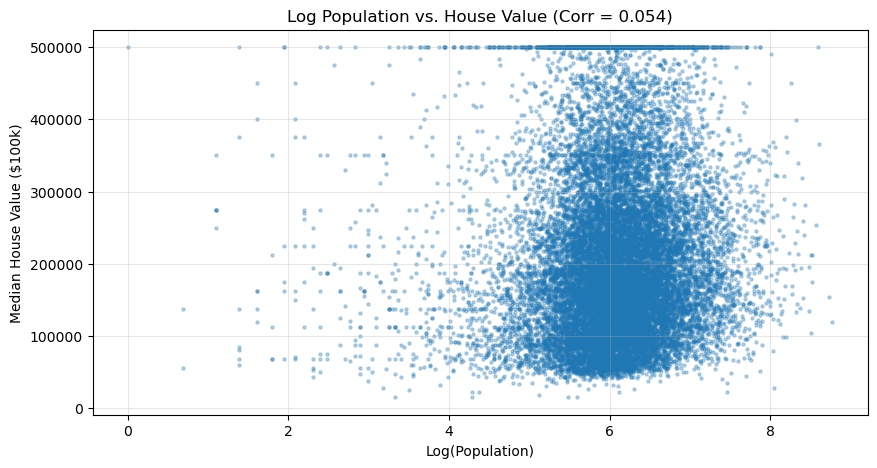

Correlation: 0.054
Verdict: Weak negative relationship - higher population areas tend to have slightly lower values
Caveat: Population is highly skewed and log transformation helps but doesn't fix spatial clustering

ALTERNATIVE HYPOTHESIS B: Rooms per capita predicts house value


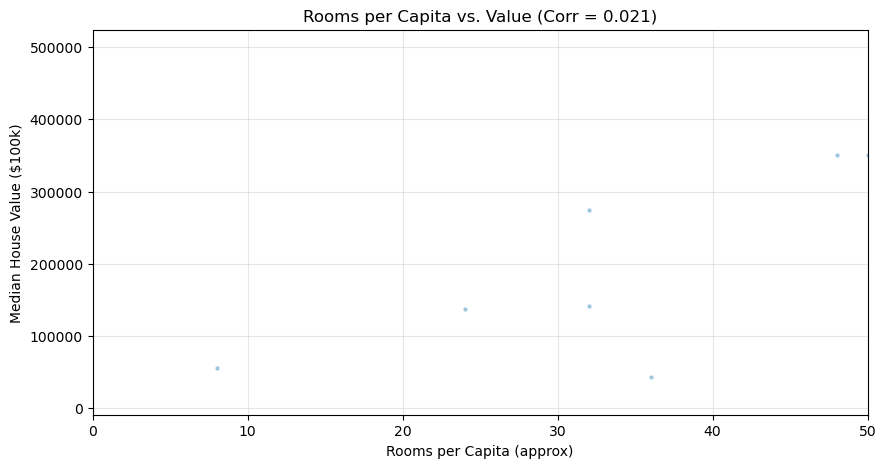

Correlation: 0.021
Verdict: Moderate positive correlation - more space per person = higher values
Caveat: This is a constructed feature with measurement error and potential endogeneity issues


In [38]:
# Option A: Population density vs house value
print("\n" + "="*60)
print("ALTERNATIVE HYPOTHESIS A: High population areas have lower house values")
print("="*60)

homes['log_population'] = np.log(homes['Population'])
corr_pop = homes['log_population'].corr(homes['MedHouseVal'])

plt.figure(figsize=(10, 5))
plt.scatter(homes['log_population'], homes['MedHouseVal'], alpha=0.3, s=5)
plt.xlabel('Log(Population)')
plt.ylabel('Median House Value ($100k)')
plt.title(f'Log Population vs. House Value (Corr = {corr_pop:.3f})')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Correlation: {corr_pop:.3f}")
print("Verdict: Weak negative relationship - higher population areas tend to have slightly lower values")
print("Caveat: Population is highly skewed and log transformation helps but doesn't fix spatial clustering")

# Option B: Combined feature - rooms per capita
print("\n" + "="*60)
print("ALTERNATIVE HYPOTHESIS B: Rooms per capita predicts house value")
print("="*60)

homes['rooms_per_capita'] = homes['AveRooms'] * homes['AveOccup']  # Total rooms per household * occupancy = rooms per capita roughly
rooms_per_cap_corr = homes['rooms_per_capita'].corr(homes['MedHouseVal'])

plt.figure(figsize=(10, 5))
plt.scatter(homes['rooms_per_capita'], homes['MedHouseVal'], alpha=0.3, s=5)
plt.xlabel('Rooms per Capita (approx)')
plt.ylabel('Median House Value ($100k)')
plt.title(f'Rooms per Capita vs. Value (Corr = {rooms_per_cap_corr:.3f})')
plt.grid(True, alpha=0.3)
plt.xlim(0, 50)  # Trim extreme outliers for better visualization
plt.show()

print(f"Correlation: {rooms_per_cap_corr:.3f}")
print("Verdict: Moderate positive correlation - more space per person = higher values")
print("Caveat: This is a constructed feature with measurement error and potential endogeneity issues")